# Task-2 Week-3.

**Dataset :-** 'Admission_Prediction.csv'

**Objective :-Perform one-way and multi-way ANOVA tests to evaluate and compare mean differences across multiple applicant groups, such as different academic disciplines or test score bands

In [18]:
# Import libraries

import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [19]:
# Load the dataset

df = pd.read_csv("Admission_Prediction.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (1000, 13)

First 5 Records:
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  Research  Chance of Admit  Year  \
0           1        337          118                  4  4.5  4.5  9.65         1             0.92  2022   
1           2        324          107                  4  4.0  4.5  8.87         1             0.76  2022   
2           3        316          104                  3  3.0  3.5  8.00         1             0.72  2022   
3           4        322          110                  3  3.5  2.5  8.67         1             0.80  2022   
4           5        314          103                  2  2.0  3.0  8.21         0             0.65  2022   

                              University_Name region Admission Status  
0    Indian Institute of Technology Kharagpur   East         Accepted  
1  National Institute of Technology Karnataka  South         Accepted  
2                          Gujarat University   West         Rejected  
3            

In [20]:
# Check for missing values
print(df.isnull().sum())

dependent_variable = "Chance of Admit"

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
Year                 0
University_Name      0
region               0
Admission Status     0
dtype: int64


In [21]:
# Perform One-Way ANOVA

# Create groups based on University Rating
groups = [
    group["Chance of Admit"].dropna().values
    for _, group in df.groupby("University Rating")
]

# Perform One-Way ANOVA
f_statistic, p_value = stats.f_oneway(*groups)

print("One-Way ANOVA Results")
print("F-Statistic:", round(f_statistic, 4))
print("P-Value:", p_value)

# Decision
if p_value < 0.05:
    print("Reject the Null Hypothesis")
    print("A significant difference exists between group means.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("No statistically significant difference was detected.")

One-Way ANOVA Results
F-Statistic: 11.5868
P-Value: 3.36969204968112e-09
Reject the Null Hypothesis
A significant difference exists between group means.


In [22]:
# Compare the group means

group_summary = df.groupby("University Rating")[
    "Chance of Admit"
].agg(["count", "mean", "std"])

print(group_summary.round(4))

                   count    mean     std
University Rating                       
1                    149  0.6928  0.1558
2                    235  0.6772  0.1309
3                    246  0.7188  0.1260
4                    192  0.7474  0.1467
5                    178  0.7587  0.1633


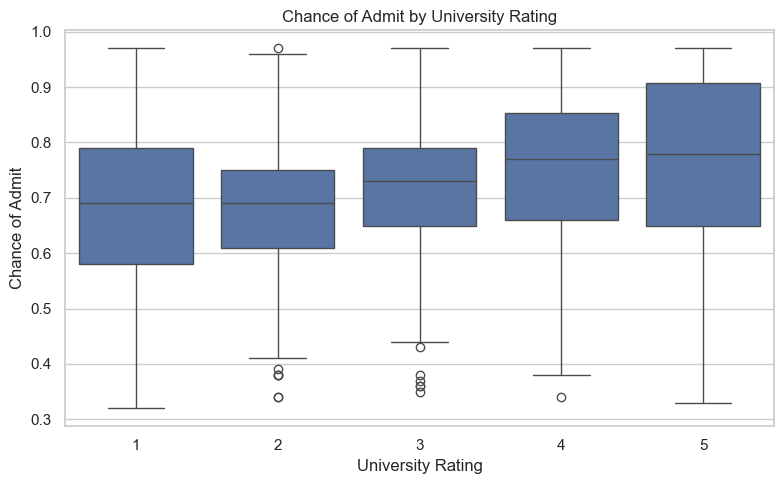

In [23]:
# Visualize the results

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="University Rating",
    y="Chance of Admit"
)

plt.title("Chance of Admit by University Rating")
plt.xlabel("University Rating")
plt.ylabel("Chance of Admit")
plt.tight_layout()
plt.show()

In [24]:
# Perform Multi-Way ANOVA (Two-Way ANOVA)

# Two-Way ANOVA with interaction
model = ols(
    'Q("Chance of Admit") ~ '
    'C(Q("University Rating")) * C(Research)',
    data=df
).fit()

# Generate ANOVA table
anova_results = sm.stats.anova_lm(model, typ=2)

print("Two-Way ANOVA Results")
print(anova_results)

Two-Way ANOVA Results
                                          sum_sq     df          F        PR(>F)
C(Q("University Rating"))               0.574777    4.0   7.473138  6.245183e-06
C(Research)                             0.969499    1.0  50.420924  2.366093e-12
C(Q("University Rating")):C(Research)   0.316602    4.0   4.116389  2.587664e-03
Residual                               19.035828  990.0        NaN           NaN


In [25]:
# Compare the groups in the multi-way analysis

multi_group_summary = df.groupby(
    ["University Rating", "Research"]
)["Chance of Admit"].agg(["count", "mean", "std"])

print(multi_group_summary.round(4))

                            count    mean     std
University Rating Research                       
1                 0            93  0.6786  0.1591
                  1            56  0.7164  0.1484
2                 0           142  0.6599  0.1219
                  1            93  0.7038  0.1401
3                 0           124  0.7010  0.1249
                  1           122  0.7370  0.1249
4                 0            70  0.6966  0.1452
                  1           122  0.7766  0.1400
5                 0            68  0.6754  0.1351
                  1           110  0.8102  0.1584


In [26]:
# Check ANOVA assumptions

# Check equal variances for One-Way ANOVA
rating_groups = [
    group["Chance of Admit"].dropna().values
    for _, group in df.groupby("University Rating")
]

levene_stat, levene_p = stats.levene(
    *rating_groups,
    center="median"
)

print("Levene Statistic:", round(levene_stat, 4))
print("Levene P-Value:", levene_p)

if levene_p < 0.05:
    print("Warning: Group variances may not be equal.")
else:
    print("No significant evidence of unequal variances.")

Levene Statistic: 7.59
Levene P-Value: 5.0435101762385056e-06
